# Maize Yield Prediction for Smallholder Farmers

**Mission:** help smallholder farmers, especially young farmers, grow more food with less guesswork.

**Use case:** predict maize yield (kg per hectare) from farm conditions and practices.

**Who uses it and what for:** farmers and agricultural extension officers use the predicted yield to plan which practices (fertiliser, planting date, seed type) to focus on before the season.

**Dataset:** One Acre Fund maize survey of smallholder fields in Sub-Saharan Africa, 2016-2022 (Zenodo: https://zenodo.org/doi/10.5281/zenodo.11115815), licence CC BY 4.0.

In [66]:
import pandas as pd

df = pd.read_csv("/One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv", low_memory=False)
print(df.shape)
df.head()

(14773, 53)


,year,country,iso,season,cz,lon,lat,strat,avg_season_gdd,avg_season_ai,...,manure,fert_in_hole,lime_kg_ha,weeding,pesticide,disease,pest,striga,water_excess,yield_kg_ha
0,2016,kenya,KEN,first season,7701,34.067,0.227,01_KEN7701S1,2509.099854,0.998492,...,NaN,True,0.0,NaN,NaN,False,False,NaN,False,1462.951369
1,2017,kenya,KEN,first season,7701,34.100,0.238,01_KEN7701S1,2552.900146,1.038017,...,NaN,True,0.0,False,True,False,True,NaN,False,2817.771269
2,2019,kenya,KEN,first season,7701,34.082,0.247,01_KEN7701S1,2580.099854,1.008526,...,NaN,True,0.0,False,False,False,True,NaN,False,0.000000
3,2020,kenya,KEN,first season,7701,34.098,0.232,01_KEN7701S1,2562.800049,1.018445,...,True,False,0.0,True,False,False,True,True,False,4788.722787
4,2020,kenya,KEN,first season,7701,34.094,0.272,01_KEN7701S1,2612.800049,1.023641,...,NaN,False,0.0,False,NaN,False,False,True,False,2193.982268


### Missing values

Several columns have many blank values. The biggest gaps are in `manure` (13,887 rows blank), `striga` (12,249), `hyb_type` (12,191) and the other seed-trait columns (7,000 or more), because many farms did not record these details. Soil columns (such as `soil_pH` and `soil_clay`) are blank in 4,441 rows, and `row_spacing` in 6,334 rows.

Decision: I will drop columns that are blank in most rows, because there is too little real information to fill them in. For columns that are only partly blank but likely matter for yield (such as soil and planting details), I will fill the gaps in the next step instead of deleting thousands of farms.

In [67]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

,0
manure,13887
striga,12249
hyb_type,12191
hyb_yor,7903
comp_kg_ha,7726
hyb_tol_rust,7191
hyb_tol_msv,7191
hyb_tol_gls,7191
hyb_tol_ear_rot,7191
hyb_tol_mln,7191


### Maize yield (the target)

The average yield is about 2,969 kg per hectare and the middle value (median) is about 2,714. Yields vary a lot, with a standard deviation of about 1,686, and the highest is about 11,139. About 1.8% of fields have a yield of 0, which probably means a failed harvest.

Decision: I will keep the zero-yield fields, because crop failure is a real outcome that farmers face and the model should learn from it.

In [68]:
df["yield_kg_ha"].describe()

,yield_kg_ha
count,14773.000000
mean,2969.063101
std,1686.066889
min,0.000000
25%,1743.990232
50%,2713.866882
75%,3945.223578
max,11139.130825


### Feature selection

I kept 8 inputs: country, elevation, plant density (pl_m2), hybrid seed (yes/no), nitrogen (N_kg_ha), phosphorus (P_kg_ha), season rainfall and average season temperature. A farmer or extension officer can supply these, they have few or no blanks, and in a quick random forest test they were among the strongest predictors of yield.

Columns dropped and why:
- iso, cz, strat, lon, lat: codes or coordinates that duplicate country and elevation.
- plant_date, harvest_date: text dates, hard to use directly.
- manure, striga, compost, comp_kg_ha, row_spacing, hyb_* trait columns: blank in roughly 40% to 94% of rows.
- disease, pest, water_excess: only known after the season, so they cannot help plan ahead.
- Soil columns and the monthly rainfall columns: many blanks, or very similar to the rainfall and temperature columns I kept.

In [69]:
features = ["country", "elev", "pl_m2", "hybrid", "N_kg_ha", "P_kg_ha", "season_prec", "avg_season_tavg"]
target = "yield_kg_ha"

data = df[features + [target]].copy()
print(data.isna().sum())

data["hybrid"] = data["hybrid"].map({True: 1, False: 0, "True": 1, "False": 0})
data["hybrid"] = data["hybrid"].fillna(data["hybrid"].mode()[0])
data["pl_m2"] = data["pl_m2"].fillna(data["pl_m2"].median())
data["avg_season_tavg"] = data["avg_season_tavg"].fillna(data["avg_season_tavg"].median())
print("blanks left:", data.isna().sum().sum())

data = pd.get_dummies(data, columns=["country"], drop_first=True, dtype=int)
print(data.shape)
data.head()

country               0
elev                  0
pl_m2              4607
hybrid             1230
N_kg_ha               0
P_kg_ha               0
season_prec           0
avg_season_tavg      41
yield_kg_ha           0
dtype: int64
blanks left: 0
(14773, 14)


,elev,pl_m2,hybrid,N_kg_ha,P_kg_ha,season_prec,avg_season_tavg,yield_kg_ha,country_kenya,country_nigeria,country_rwanda,country_tanzania,country_uganda,country_zambia
0,1280,3.402686,1.0,51.892050,24.71050,677.039708,21.275661,1462.951369,1,0,0,0,0,0
1,1288,2.736283,1.0,51.892050,24.71050,760.532583,21.507408,2817.771269,1,0,0,0,0,0
2,1243,4.541739,1.0,27.873444,13.83788,724.153837,21.651323,0.000000,1,0,0,0,0,0
3,1271,3.986111,1.0,44.478900,49.42100,998.342599,21.559790,4788.722787,1,0,0,0,0,0
4,1226,2.277778,1.0,51.892050,24.71050,998.342599,21.824339,2193.982268,1,0,0,0,0,0


Missing values: hybrid was blank in 1,230 rows, so I filled it with the most common value (hybrid seed). pl_m2 was blank in about 4,600 rows and avg_season_tavg in 41 rows, so I filled both with the median. Burundi and Uganda have no plant density recorded at all, so those rows use the overall median, which makes the plant density less reliable there. Country was converted into 0/1 columns so the models can use it.

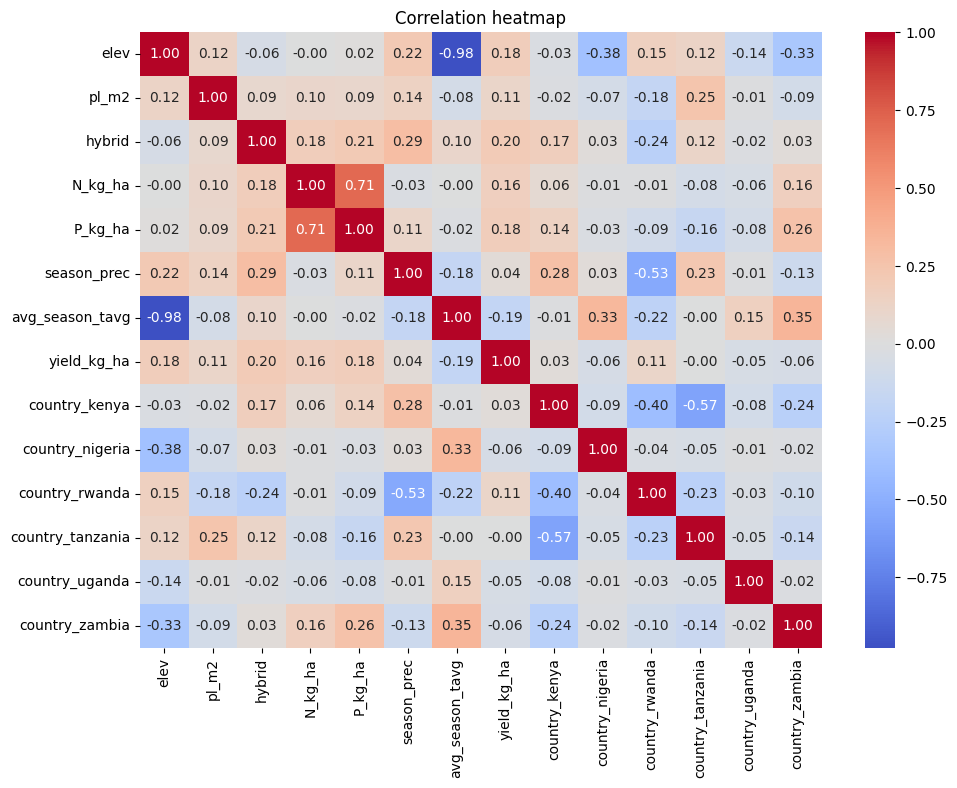

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

### Correlation heatmap

The heatmap shows that no single column is strongly linked to yield. The strongest are hybrid seed (0.20), elevation (0.18), phosphorus (0.18) and nitrogen (0.16), while average season temperature is slightly negative (-0.19). This tells me the relationships are weak and mixed, so I should expect a modest fit from a straight line.

It also shows that elevation and average season temperature are almost the same variable (correlation 0.98), because it gets cooler as altitude rises. Nitrogen and phosphorus are also linked (0.71).

Decision: I will drop average season temperature, because it repeats elevation and has some blanks. Elevation is something a farmer already knows, so the app will need 7 inputs instead of 8.

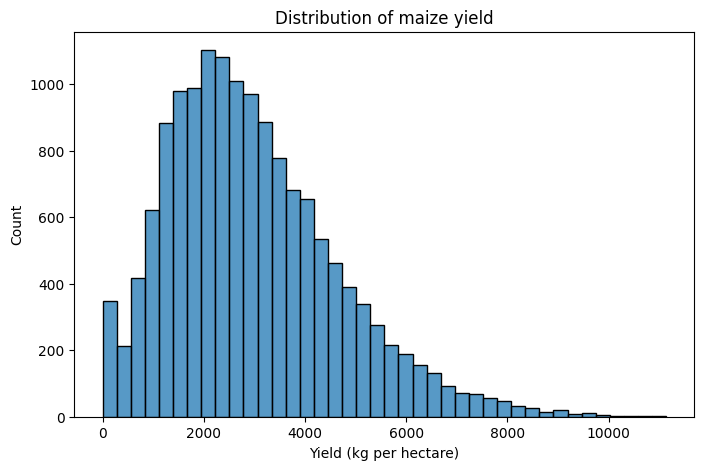

In [71]:
plt.figure(figsize=(8, 5))
sns.histplot(data["yield_kg_ha"], bins=40)
plt.xlabel("Yield (kg per hectare)")
plt.title("Distribution of maize yield")
plt.show()

### Distribution of yield

Yield is skewed to the right. About 82% of fields yield under roughly 4,500 kg per hectare, and only about 6% yield more than 6,000. There is also a small pile of fields at 0 (failed harvests).

Decision: I will keep all rows, including the very high and zero yields, because they are real outcomes. Tree models cope with skewed data well, which may help them beat the straight-line models.

In [72]:
data = data.drop(columns=["avg_season_tavg"], errors="ignore")
print(data.shape)

(14773, 13)


In [73]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.drop(columns=["yield_kg_ha"])
y = data["yield_kg_ha"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # learns the scale from the training set only
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(11818, 12) (2955, 12)


### Train/test split and standardization

I split the data into 80% for training (11,818 rows) and 20% for testing (2,955 rows). I then standardized the features so they are on a similar scale, which matters for the gradient descent model. The scaler was fitted on the training set only and then applied to the test set, so no information from the test set leaks into training.

In [74]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

models = {
    "Linear Regression (closed form)": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    results[name] = {
        "Train MSE": mean_squared_error(y_train, model.predict(X_train_scaled)),
        "Test MSE": mean_squared_error(y_test, model.predict(X_test_scaled)),
    }

pd.DataFrame(results).T.round(0)

,Train MSE,Test MSE
Linear Regression (closed form),2467171.0,2480379.0
Decision Tree,2094506.0,2348165.0
Random Forest,767841.0,2066405.0


In [75]:
from sklearn.linear_model import SGDRegressor

def train_sgd(learning_rate, alpha, epochs=50):
    model = SGDRegressor(learning_rate="constant", eta0=learning_rate, alpha=alpha, penalty="l2", random_state=42)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        model.partial_fit(X_train_scaled, y_train)
        train_losses.append(mean_squared_error(y_train, model.predict(X_train_scaled)))
        test_losses.append(mean_squared_error(y_test, model.predict(X_test_scaled)))
    return model, train_losses, test_losses

In [76]:
import matplotlib.pyplot as plt

rows = []
for lr in [0.0001, 0.001, 0.01]:
    for alpha in [0.0001, 0.01, 1]:
        for epochs in [10, 50]:
            _, tr, te = train_sgd(lr, alpha, epochs)
            rows.append({"learning_rate": lr, "alpha": alpha, "epochs": epochs,
                         "Train MSE": tr[-1], "Test MSE": te[-1]})

tuning = pd.DataFrame(rows).sort_values("Test MSE")
tuning.round(0)

,learning_rate,alpha,epochs,Train MSE,Test MSE
3,0.0,0.0,50,2468319.0,2481656.0
1,0.0,0.0,50,2467671.0,2481883.0
2,0.0,0.0,10,2474013.0,2486942.0
0,0.0,0.0,10,2473439.0,2487066.0
9,0.0,0.0,50,2487384.0,2503482.0
8,0.0,0.0,10,2487388.0,2503485.0
6,0.0,0.0,10,2486643.0,2503515.0
7,0.0,0.0,50,2486643.0,2503516.0
4,0.0,1.0,10,2566745.0,2547476.0
5,0.0,1.0,50,2566745.0,2547479.0


### Tuning SGDRegressor

I tried three learning rates (0.0001, 0.001, 0.01), three regularization strengths (alpha 0.0001, 0.01, 1) and two training lengths (10 and 50 epochs).

- Learning rate: 0.0001 gave the lowest test MSE (about 2.48 million). 0.001 was slightly worse (about 2.50 million) and 0.01 was the worst (about 2.65 million), because large steps overshoot the minimum and keep bouncing around it.
- Regularization (alpha): 0.0001 and 0.01 gave almost the same error. alpha = 1 made the error worse (about 2.55 million), because it shrinks the coefficients too much and the model underfits.
- Epochs: with the best learning rate, 50 epochs was a little better than 10 (about 2.482 million versus 2.487 million), so the loss was still improving slowly. With larger learning rates it had already stopped improving by epoch 10.

Best setting: learning rate 0.0001, alpha 0.01, 50 epochs.

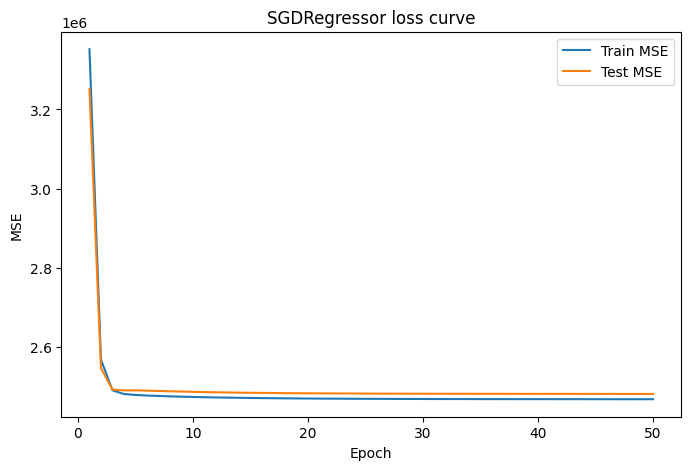

In [77]:
best_sgd, train_losses, test_losses = train_sgd(learning_rate=0.0001, alpha=0.01, epochs=50)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 51), train_losses, label="Train MSE")
plt.plot(range(1, 51), test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

### Loss curve

The loss starts high (about 3.25 million after the first epoch), drops steeply over the first 5 to 10 epochs, and then flattens out near 2.48 million. The train and test lines stay very close together, so the model is not overfitting. However, the error is still high, which tells me a straight line cannot capture the pattern in this data well (underfitting).

In [78]:
results["Linear Regression (SGD, tuned)"] = {
    "Train MSE": mean_squared_error(y_train, best_sgd.predict(X_train_scaled)),
    "Test MSE": mean_squared_error(y_test, best_sgd.predict(X_test_scaled)),
}

comparison = pd.DataFrame(results).T.round(0).sort_values("Test MSE")
comparison

,Train MSE,Test MSE
Random Forest,767841.0,2066405.0
Decision Tree,2094506.0,2348165.0
Linear Regression (closed form),2467171.0,2480379.0
"Linear Regression (SGD, tuned)",2468319.0,2481656.0


### Model comparison and best model

The Random Forest has the lowest test MSE (about 2.07 million, roughly 1,440 kg per hectare when I take the square root), followed by the Decision Tree (about 2.35 million) and the two linear models (about 2.48 million each). The best model is the one with the lowest test MSE, so I chose the Random Forest.

The two linear models score almost the same, which is expected because both fit a straight line. Their train and test errors are close, so they are not overfitting; they are underfitting, since the correlations in the heatmap were weak and a straight line cannot capture how country, seed type and fertiliser work together. The tree models can capture those combinations. The Random Forest does overfit somewhat (train MSE about 0.77 million versus test MSE about 2.07 million), but it is still clearly the most accurate on data it has not seen.

Feature most correlated with yield: P_kg_ha


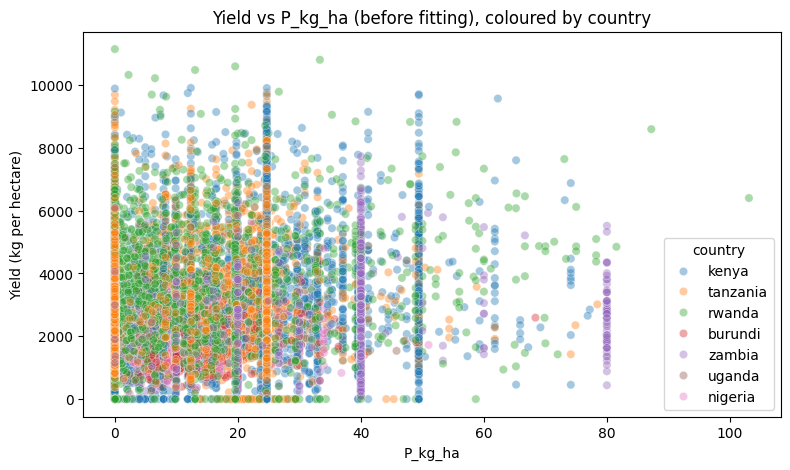

In [79]:
numeric_features = ["elev", "pl_m2", "N_kg_ha", "P_kg_ha", "season_prec"]
top_feature = data[numeric_features].corrwith(data["yield_kg_ha"]).abs().idxmax()
print("Feature most correlated with yield:", top_feature)

plot_df = pd.DataFrame({top_feature: data[top_feature], "yield_kg_ha": data["yield_kg_ha"], "country": df["country"]})

plt.figure(figsize=(9, 5))
sns.scatterplot(data=plot_df, x=top_feature, y="yield_kg_ha", hue="country", alpha=0.4)
plt.xlabel(top_feature)
plt.ylabel("Yield (kg per hectare)")
plt.title(f"Yield vs {top_feature} (before fitting), coloured by country")
plt.show()

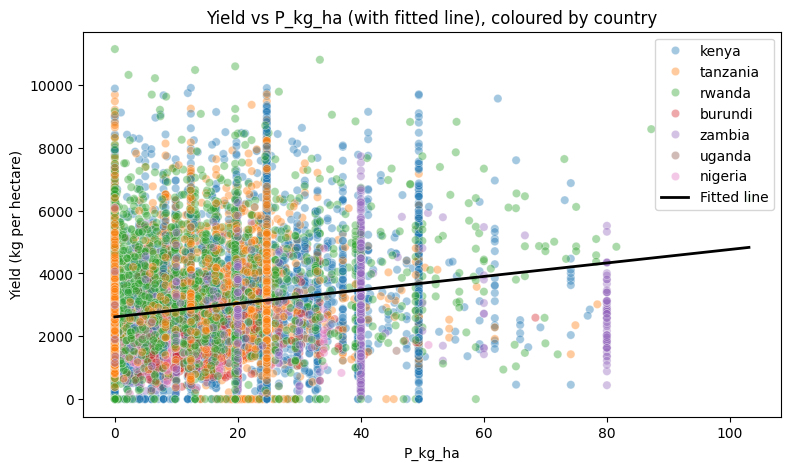

In [80]:
import numpy as np

line_model = LinearRegression()
line_model.fit(data[[top_feature]], data["yield_kg_ha"])  # used for this plot only

x_line = np.linspace(data[top_feature].min(), data[top_feature].max(), 100)
y_line = line_model.predict(pd.DataFrame({top_feature: x_line}))

plt.figure(figsize=(9, 5))
sns.scatterplot(data=plot_df, x=top_feature, y="yield_kg_ha", hue="country", alpha=0.4)
plt.plot(x_line, y_line, color="black", linewidth=2, label="Fitted line")
plt.xlabel(top_feature)
plt.ylabel("Yield (kg per hectare)")
plt.title(f"Yield vs {top_feature} (with fitted line), coloured by country")
plt.legend()
plt.show()

### Scatter plots

The scatter plot shows yield against phosphorus applied (the number-type feature most correlated with yield, at about 0.18). The points form a wide, loose cloud, and the fitted red line slopes gently upward: more phosphorus goes with slightly higher yield. Because the points are so spread out, phosphorus alone explains only about 3% of the variation in yield. This fits what the heatmap showed, and it is why a model that combines several features does better than one straight line.

In [81]:
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

feature_cols = ["country", "elev", "pl_m2", "hybrid", "N_kg_ha", "P_kg_ha", "season_prec"]
numeric_cols = ["elev", "pl_m2", "hybrid", "N_kg_ha", "P_kg_ha", "season_prec"]

raw = df[feature_cols + ["yield_kg_ha"]].copy()
raw["hybrid"] = raw["hybrid"].map({True: 1, False: 0, "True": 1, "False": 0})

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    raw[feature_cols], raw["yield_kg_ha"], test_size=0.2, random_state=42)

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["country"]),
])
best_pipeline = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1)),
])
best_pipeline.fit(Xr_train, yr_train)

print("Final model test MSE:", round(mean_squared_error(yr_test, best_pipeline.predict(Xr_test))))

joblib.dump(best_pipeline, "best_model.pkl", compress=3)
print("scikit-learn version used:", sklearn.__version__)

Final model test MSE: 2063849
scikit-learn version used: 1.6.1


In [82]:
from google.colab import files
files.download("best_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [83]:
def predict_one_row(index=0):
    model = joblib.load("best_model.pkl")
    row = Xr_test.iloc[[index]]
    prediction = model.predict(row)[0]
    print("Inputs:", row.to_dict("records")[0])
    print("Predicted yield:", round(prediction, 1), "kg/ha")
    print("Actual yield:", round(yr_test.iloc[index], 1), "kg/ha")
    return prediction

predict_one_row(0)

Inputs: {'country': 'rwanda', 'elev': 1636, 'pl_m2': nan, 'hybrid': 0.0, 'N_kg_ha': 0.0, 'P_kg_ha': 0.0, 'season_prec': 620.79961013794}
Predicted yield: 2971.3 kg/ha
Actual yield: 4426.7 kg/ha


np.float64(2971.31924831129)

### Saving the model and predicting one row

The Random Forest is saved together with its preprocessing (filling blanks, scaling, and encoding country) in one scikit-learn Pipeline, using joblib, in best_model.pkl. This means it can take a raw row of farm data directly. The function above loads the saved file and predicts the yield for one row of the test set; the API will reuse this function.

elev           0.29
pl_m2          0.18
country        0.15
season_prec    0.14
hybrid         0.13
N_kg_ha        0.06
P_kg_ha        0.05
dtype: float64


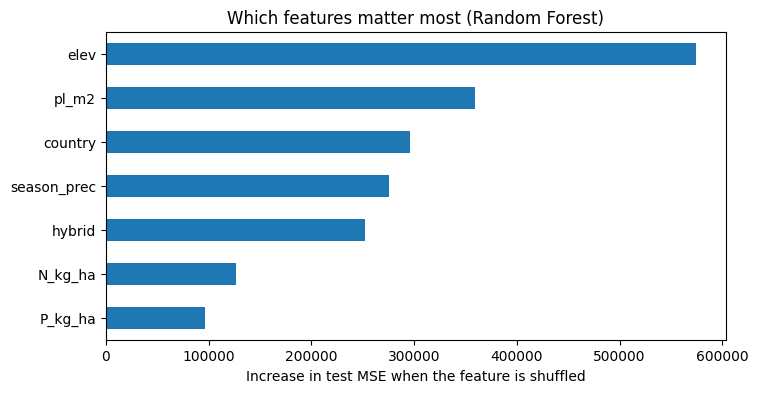

In [84]:
from sklearn.inspection import permutation_importance

result = permutation_importance(best_pipeline, Xr_test, yr_test,
                                scoring="neg_mean_squared_error", n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=Xr_test.columns).sort_values(ascending=False)
print((importance / importance.sum()).round(2))

importance.sort_values().plot(kind="barh", figsize=(8, 4))
plt.xlabel("Increase in test MSE when the feature is shuffled")
plt.title("Which features matter most (Random Forest)")
plt.show()

### Which features matter most

I measured importance by shuffling each column in the test set and seeing how much the test MSE got worse. Elevation matters most (about 29% of the total), followed by plant density (18%), country (15%), season rainfall (14%) and hybrid seed (13%). Nitrogen (6%) and phosphorus (5%) matter least.

Why each input was kept:
- elev: the strongest feature; it also stands in for temperature, which falls as elevation rises (correlation 0.98).
- pl_m2: plant density changes how much each plant can yield.
- country: captures differences in soil, climate and farming systems.
- season_prec: rain is the main driver of rain-fed maize.
- hybrid: hybrid seed is bred for higher yield.
- N_kg_ha and P_kg_ha: they matter least here, but fertiliser is what a farmer can change, so I kept them for "what if" questions.

The heatmap showed hybrid seed, elevation and phosphorus as the strongest straight-line links, but the Random Forest also finds plant density, country and rainfall important. Those effects are not straight lines, which helps explain why the Random Forest beats the linear models.

In [85]:
print([round(x) for x in test_losses[-5:]])
change = (test_losses[-10] - test_losses[-1]) / test_losses[-1] * 100
print(f"Change in test MSE over the last 10 epochs: {change:.4f}%")

[2481700, 2481688, 2481676, 2481666, 2481656]
Change in test MSE over the last 10 epochs: 0.0051%


By epoch 50 the test MSE changes by less than 0.01% over the last 10 epochs, so training had converged and was not stopped early.

### Is the test loss high or low?

The best model's test MSE is about 2.06 million, which is a typical error (RMSE) of about 1,440 kg per hectare. The average yield is about 2,970 kg per hectare, so a typical prediction is off by nearly half of the average. The model explains only about 26% of the variation in yield (R² about 0.26), although its error is 26% lower than always guessing the average (test MSE 2.80 million). So the loss is high in absolute terms, which is normal for noisy real farm data.

To reduce it, I would collect the columns I dropped for being mostly blank (seed maturity, soil, row spacing), add more detailed weather and soil data, and tune the Random Forest (more trees, depth, leaf size).